In [1]:
import pandas as pd
import numpy as np

df_test = pd.read_csv('../data/test.csv')
df_train = pd.read_csv('../data/train.csv')

df_summary = pd.DataFrame({'dtype': df_train.dtypes, 'nulls': df_train.isna().sum(), 'nununique': df_train.nunique(), 'sample_1': df_train.iloc[0], 'sample_2': df_train.iloc[1], 'sample_3': df_train.iloc[2]})
df_summary



,dtype,nulls,nununique,sample_1,sample_2,sample_3
Id,int64,0,1460,1,2,3
MSSubClass,int64,0,15,60,20,60
MSZoning,str,0,5,RL,RL,RL
LotFrontage,float64,259,110,65.0,80.0,68.0
LotArea,int64,0,1073,8450,9600,11250
...,...,...,...,...,...,...
MoSold,int64,0,12,2,5,9
YrSold,int64,0,5,2008,2007,2008
SaleType,str,0,9,WD,WD,WD
SaleCondition,str,0,6,Normal,Normal,Normal


In [2]:
for df in [df_train, df_test]:
    df['Total_SF'] = df['GrLivArea'] + df['TotalBsmtSF']
    df['Total_Bathrooms'] = df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'] + df['FullBath'] + 0.5 * df['HalfBath']
    df['AgeAtSale'] = df['YrSold'] - df['YearBuilt']
    df['GarageSFPerCar'] = df['GarageArea'] / df['GarageCars']

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning:

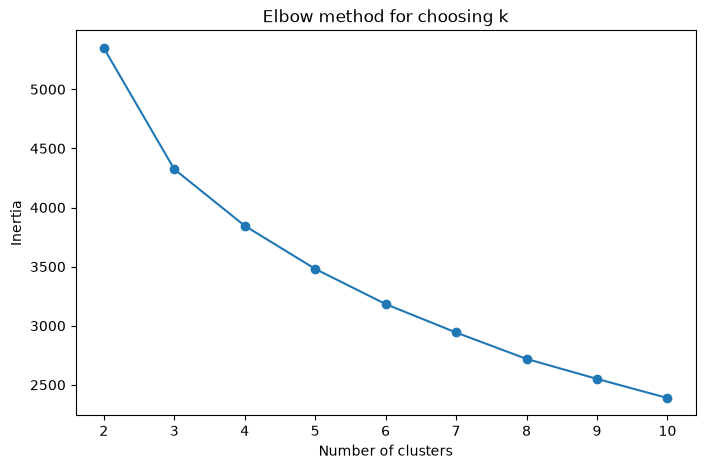

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

cluster_cols = ['GrLivArea', 'OverallQual', 'YearBuilt', 'GarageCars', 'TotalBsmtSF', 'Total_SF']

X_cluster = df_train[cluster_cols].copy()
X_cluster = X_cluster.fillna(X_cluster.median())
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

inertias = []

for k in range (2,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow method for choosing k')
plt.xticks(range(2,11))
plt.show()



c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


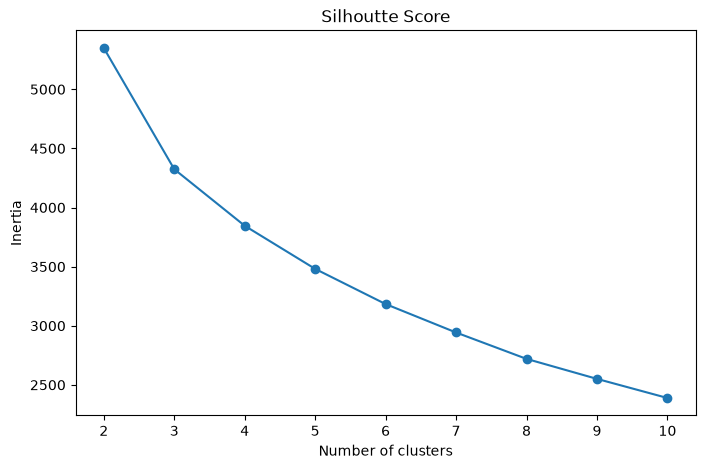

In [4]:
silhoutte_scores = []
for k in range(2,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

score = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)

silhoutte_scores.append(score)

plt.figure(figsize=(8,5))
plt.plot(
    range(2,11),
    inertias,
    marker='o'
)

plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Silhoutte Score')
plt.xticks(range(2,11))
plt.show()

In [5]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

cluster_labels = final_kmeans.fit_predict(X_cluster_scaled)

cluster_analysis = df_train[cluster_cols + ['SalePrice']]
cluster_analysis['Cluster'] = cluster_labels
cluster_analysis['LogSalePrice'] = np.log1p(cluster_analysis['SalePrice'])

cluster_summary = (
    cluster_analysis.groupby('Cluster').agg(
        house_count=('SalePrice', 'size')
        , avergae_grlivarea=('GrLivArea', 'mean'),
        average_quality=('OverallQual', 'mean'),
        average_year_built=('YearBuilt', 'mean'),
        average_total_sf=('Total_SF', 'mean'),
        median_log_price=('LogSalePrice', 'median')
    ).sort_values('median_log_price')
)

cluster_summary

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,house_count,avergae_grlivarea,average_quality,average_year_built,average_total_sf,median_log_price
Cluster,,,,,,
0,607,1195.408567,5.019769,1947.026359,2011.219110,11.744045
2,601,1556.103161,6.409318,1986.174709,2621.419301,12.106258
1,252,2189.468254,7.960317,1994.107143,3810.083333,12.565496


In [6]:
df_train['HouseCluster'] = cluster_labels

train_distances = final_kmeans.transform(X_cluster_scaled)
df_train['ClusterDistance'] = train_distances.min(axis=1)



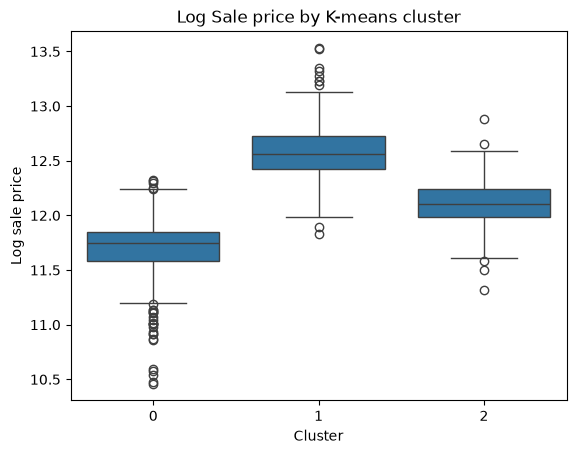

In [7]:
import seaborn as sns

sns.boxplot(data=cluster_analysis, x='Cluster', y='LogSalePrice')
plt.title('Log Sale price by K-means cluster')
plt.xlabel('Cluster')
plt.ylabel('Log sale price')
plt.show()

In [8]:
num_cols = df_train.select_dtypes(include='number').columns.tolist()

cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

ord_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageCond', 'GarageQual', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

cat_cols = [col for col in cat_cols if col not in ord_cols]

ord_cols = [col for col in ord_cols if col in df_train.columns]

num_cols = [col for col in num_cols if col != 'SalePrice' and col != 'Id']

C:\Users\yazid\AppData\Local\Temp\ipykernel_23708\2204705351.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [9]:

quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
quality_order_none = ['None'] + quality_order
exposure_none_order = ['None', 'No', 'Mn', 'Av', 'Gd']
finish_none_order = ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
pool_none_order = ['None', 'Fa', 'Gd', 'Ex']

regular_ord_cols = ['ExterQual', 'ExterCond', 'HeatingQC', 'KitchenQual']
none_ord_cols = ['BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'GarageCond', 'GarageQual', 'PoolQC', 'FireplaceQu']
print(cat_cols)
none_cat_cols = ['Alley', 'MasVnrType', 'GarageType', 'GarageFinish', 'Fence', 'MiscFeature']
regular_cat_cols = [col for col in cat_cols if col not in none_cat_cols]
regular_cat_cols.append('HouseCluster')


['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [10]:

ordinal_categories = {
    'ExterQual': quality_order,
    'ExterCond': quality_order,
    'BsmtQual': quality_order_none,
    'BsmtCond': quality_order_none,
    'HeatingQC': quality_order,
    'KitchenQual': quality_order,
    'FireplaceQu': quality_order_none,
    'GarageCond': quality_order_none,
    'GarageQual': quality_order_none,
    'PoolQC': pool_none_order,
    'BsmtExposure': exposure_none_order,
    'BsmtFinType1': finish_none_order,
    'BsmtFinType2': finish_none_order
}

regular_categories = [ordinal_categories[col] for col in regular_ord_cols]
none_categories = [ordinal_categories[col] for col in none_ord_cols]



In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

num_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='median'))])
regular_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
none_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
regular_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=regular_categories, handle_unknown='use_encoded_value', unknown_value=-1))])
none_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('ordinal', OrdinalEncoder(categories=none_categories, handle_unknown='use_encoded_value', unknown_value=-1))])

param_distributions = {
    'model__n_estimators': [100, 300, 600, 1000],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_depth': [2,3,4,5,6],
    'model__min_child_weight': [1,3,5],
    'model__subsample': [0.8,0.9,1.0]
}
preprocessor = ColumnTransformer(transformers=[('num', num_pipeline, num_cols), ('regular_cat', regular_cat_pipeline, regular_cat_cols), ('none_cat', none_cat_pipeline, none_cat_cols), ('regular_ord', regular_ord_pipeline, regular_ord_cols), ('none_ord', none_ord_pipeline, none_ord_cols)])

model1 = XGBRegressor(learning_rate=0.01, n_estimators=100, random_state=42, max_depth=6)

full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model1)])

X_train = df_train.drop(columns=['SalePrice', 'Id'])
X_test = df_test.drop(columns=['Id'])
y_train = np.log1p(df_train['SalePrice'])
test_id = df_test['Id']

In [12]:
from sklearn.dummy import DummyRegressor
from xgboost import cv
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyRegressor(strategy='mean')

baseline_scores = cross_val_score(
    baseline, 
    X_train,
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

baseline_rmsle = np.sqrt(-baseline_scores.mean())

In [13]:

msle = cross_val_score(full_pipeline, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')
rmsle = np.sqrt(-msle.mean())

print(baseline_rmsle, rmsle)

0.3995729236866519 0.21361563920868828


In [14]:
search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='neg_mean_squared_error',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True,
    refit=False,
    error_score='raise'
)

search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)

In [15]:
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__subsample,param_model__n_estimators,param_model__min_child_weight,param_model__max_depth,param_model__learning_rate,params,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,3.842844,0.091396,0.066384,0.001706,0.9,300,3,6,0.03,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.017909,0.005472,12,-9.272461e-04,-8.501088e-04,-8.249784e-04,-8.716890e-04,-8.806546e-04,-8.709354e-04,3.409315e-05
1,2.004717,0.174920,0.106437,0.042575,1.0,100,1,5,0.03,"{'model__subsample': 1.0, 'model__n_estimators...",...,-0.021100,0.003992,22,-6.407666e-03,-6.317932e-03,-6.256199e-03,-6.325093e-03,-6.722357e-03,-6.405849e-03,1.654245e-04
2,2.230167,0.565914,0.090074,0.020868,0.8,600,3,3,0.01,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.018049,0.004606,17,-8.838807e-03,-9.083672e-03,-8.221366e-03,-9.026822e-03,-9.153807e-03,-8.864895e-03,3.383381e-04
3,1.433615,0.077195,0.108906,0.066499,0.8,600,3,2,0.03,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.017294,0.004602,7,-7.740991e-03,-7.806847e-03,-7.393301e-03,-8.007653e-03,-7.985331e-03,-7.786824e-03,2.215999e-04
4,3.996728,0.070639,0.120896,0.060680,0.8,1000,3,4,0.05,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.017006,0.004753,4,-1.673057e-04,-1.977878e-04,-1.707140e-04,-1.981557e-04,-1.871496e-04,-1.842226e-04,1.307958e-05
5,0.975974,0.143376,0.056412,0.013166,1.0,300,5,3,0.01,"{'model__subsample': 1.0, 'model__n_estimators...",...,-0.022401,0.003826,26,-1.526478e-02,-1.594603e-02,-1.423715e-02,-1.545045e-02,-1.626959e-02,-1.543360e-02,6.959506e-04
6,0.866231,0.046147,0.081400,0.015639,0.8,300,5,3,0.01,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.021906,0.003631,24,-1.528291e-02,-1.590429e-02,-1.423658e-02,-1.535254e-02,-1.606305e-02,-1.536787e-02,6.416083e-04
7,1.570804,0.132760,0.096767,0.022756,0.9,100,1,6,0.01,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.044879,0.006589,29,-3.230056e-02,-3.364964e-02,-3.414284e-02,-3.259552e-02,-3.477351e-02,-3.349241e-02,9.288602e-04
8,2.026468,0.162016,0.074520,0.016332,0.9,300,1,5,0.03,"{'model__subsample': 0.9, 'model__n_estimators...",...,-0.017570,0.004529,10,-1.789483e-03,-1.786196e-03,-1.719212e-03,-1.807276e-03,-1.843255e-03,-1.789084e-03,4.038841e-05
9,1.178102,0.093548,0.095406,0.021071,0.8,600,5,2,0.05,"{'model__subsample': 0.8, 'model__n_estimators...",...,-0.018036,0.005167,16,-5.949921e-03,-5.991500e-03,-5.741881e-03,-6.515343e-03,-6.417430e-03,-6.123215e-03,2.943204e-04


In [16]:
results['train_rmsle'] = np.sqrt(-results['mean_train_score'])

results['validation_rmsle'] = np.sqrt(
    -results['mean_test_score']
)

results['overfit_gap'] = (
    results['validation_rmsle'] - results['train_rmsle']
)

max_gap = 0.05

accepted_results = results[results['overfit_gap'] <= max_gap]

best_index = accepted_results['validation_rmsle'].idxmin()

best_params = results.loc[best_index, 'params']

In [17]:
from sklearn.base import clone

final_pipeline = clone(full_pipeline)
final_pipeline.set_params(**best_params)
final_pipeline.fit(X_train, y_train)

selected_scores = -cross_val_score(
    final_pipeline, 
    X_train, 
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

print("Selected RMSLE:", np.sqrt(selected_scores.mean()))

Selected RMSLE: 0.13108617783392232


In [34]:
model = final_pipeline.named_steps['model']
preprocessor = final_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

quality_analysis = (
    df_train.assign(LogSalePrice=np.log1p(df_train['SalePrice'])).groupby('ExterQual').agg(house_count=('LogSalePrice', 'size'), median_log_price=('LogSalePrice', 'median'), mean_log_price=(
        'LogSalePrice', 'mean'
    )).sort_values('median_log_price')
)

quality_analysis

,house_count,median_log_price,mean_log_price
ExterQual,,,
Fa,14,11.317526,11.304554
TA,906,11.845468,11.837993
Gd,488,12.301387,12.311287
Ex,52,12.806550,12.764047


In [35]:
numeric_df = df_train.select_dtypes(include='number').copy()

numeric_df['LogSalePrice'] = np.log1p(numeric_df['SalePrice'])

correlations = (numeric_df.corr()['LogSalePrice'].drop('LogSalePrice').sort_values(key=abs, ascending=False))

print(correlations.head(15))

SalePrice          0.948374
OverallQual        0.817185
Total_SF           0.773277
GrLivArea          0.700927
GarageCars         0.680625
Total_Bathrooms    0.673011
GarageArea         0.650888
TotalBsmtSF        0.612134
1stFlrSF           0.596981
FullBath           0.594771
AgeAtSale         -0.587290
YearBuilt          0.586570
YearRemodAdd       0.565608
GarageYrBlt        0.541073
TotRmsAbvGrd       0.534422
Name: LogSalePrice, dtype: float64


In [36]:
car_size = pd.DataFrame(df_train['GarageArea'] / df_train['GarageCars'])
car_size

,0
0,274.000000
1,230.000000
2,304.000000
3,214.000000
4,278.666667
...,...
1455,230.000000
1456,250.000000
1457,252.000000
1458,240.000000


In [37]:
from sklearn.feature_selection import mutual_info_regression

numeric_cols = df_train.select_dtypes(include='number').columns.tolist()
numeric_cols.remove('SalePrice')
numeric_cols.remove('Id')
X_numeric = df_train[numeric_cols].copy()

X_numeric = X_numeric.fillna(X_numeric.median())

y_log = np.log1p(df_train['SalePrice'])
mi_scores = mutual_info_regression(X_numeric, y_log, random_state=42)

mi_results = (
    pd.Series(mi_scores, index=numeric_cols).sort_values(ascending=False)
)

print(mi_results.head(20))

Total_SF           0.669716
OverallQual        0.571149
GrLivArea          0.456818
GarageArea         0.364214
TotalBsmtSF        0.361761
YearBuilt          0.361034
GarageCars         0.358765
Total_Bathrooms    0.340320
AgeAtSale          0.333316
1stFlrSF           0.298676
MSSubClass         0.287179
GarageYrBlt        0.285374
FullBath           0.268780
YearRemodAdd       0.232656
LotFrontage        0.230772
TotRmsAbvGrd       0.225506
2ndFlrSF           0.204575
LotArea            0.170957
OpenPorchSF        0.163962
Fireplaces         0.158848
dtype: float64


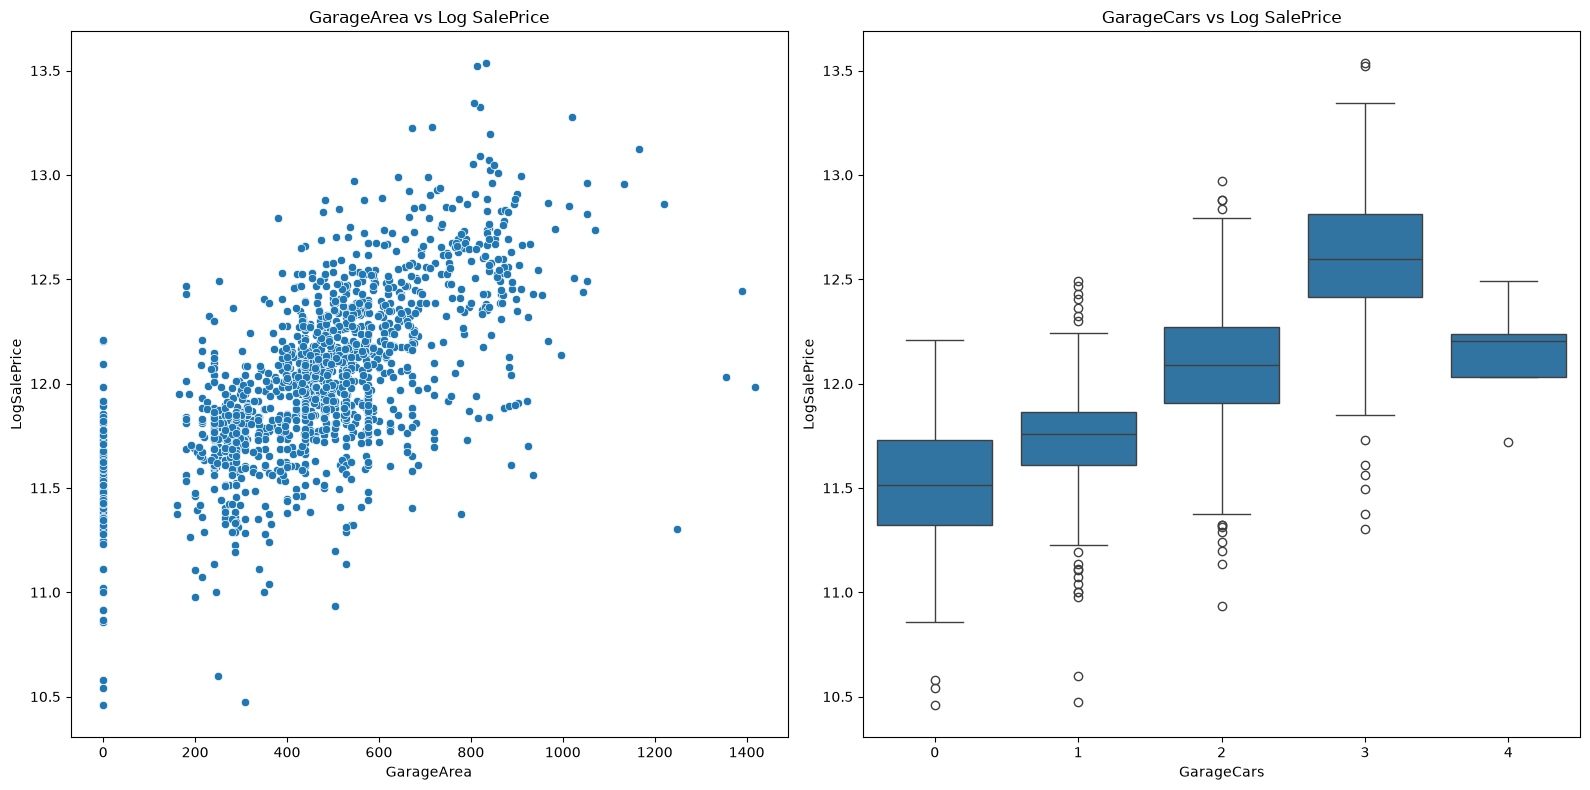

In [ ]:

import seaborn as sns

plot_data = df_train.copy()
plot_data['LogSalePrice'] = np.log1p(plot_data['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(16,8))

sns.scatterplot(data=plot_data,
                x='GarageArea', 
                y='LogSalePrice',
                ax=axes[0])

axes[0].set_title('GarageArea vs Log SalePrice')

sns.boxplot(data=plot_data, x='GarageCars', y='LogSalePrice', ax=axes[1])

axes[1].set_title('GarageCars vs Log SalePrice')
plt.tight_layout()
plt.savefig('garage_vis.png', bbox_inches='tight')
plt.show()

